# What's Driving Negative Duolingo Reviews, and Do Those Complaints Get Better or Worse After App Updates?

*Teenna Pachika and Johanna Garcia · INFO 4360 Course Project · Final Report*

Duolingo is one of the most popular language-learning apps in the world, and most of its Google Play reviews are glowing: 87% give it 4 or 5 stars. But behind those good ratings is a smaller group of unhappy users. In just six weeks this summer, about 4,150 people left a 1- or 2-star review. These users matter because they are the most likely to quit the app, and their reviews are what new users read before they download it.

The problem is that a star rating only tells you that someone is unhappy, not *why*. Duolingo's product team can't read thousands of reviews by hand, so they need a faster way to see what people are complaining about and when it changes. In this report, we find the most common complaints in negative reviews, check whether any of them grew after recent app updates, and turn that into clear recommendations to help the team decide what to fix first.

### How to read this report
Each section builds on the one before it. We start with the data, recap what simple text analysis told us in Phase 2, and then show how we used Claude, an AI model, to label every negative review by complaint type. Finally, we look at how those complaints changed over time and which ones other users agreed with most, and we turn that into recommendations. The code is here so anyone can check our work, but you can follow the story by reading only the text and the charts.

### Contents
1. **The Data:** where the reviews come from and how we cleaned them
2. **What We Learned First:** keywords, sentiment, and topics from Phase 2
3. **Using Claude to Label Complaints:** our prompt, sample outputs, quality checks, and cost
4. **What the Complaints Tell Us:** complaints over time and the ones users agree with most
5. **Key Findings**
6. **What Duolingo Should Do:** recommendations, limitations, and risks
7. **Ethics and Privacy**
8. **AI Usage Log**

In [6]:
# Setting up: libraries, our shared functions, and the data
import sys
sys.path.append("..")

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.preprocessing import load_reviews, get_negative

df = load_reviews()
neg = get_negative(df)

# Showing a chart we already saved in the figures folder (it gets embedded in the HTML export)
def show_figure(name, width=500):
    """Display a saved chart from the figures folder."""
    display(Image(filename=f"../figures/{name}.png", width=width))

print(f"All reviews: {len(df):,} | Negative reviews (1-2 stars): {len(neg):,} ({len(neg) / len(df):.1%})")

All reviews: 50,000 | Negative reviews (1-2 stars): 4,147 (8.3%)


## 1. The Data

We collected our own data. Using a Python package called `google-play-scraper` (see `collect_reviews.ipynb`), we downloaded **50,000 Google Play reviews** of the Duolingo app from US users writing in English. The reviews cover about six weeks, from **July 29 to September 6, 2026** (there is only one review after September 6, so we stop there when we look at trends over time).

Each review has six pieces of information:

| Column | What it means |
|---|---|
| `reviewId` | A unique ID for each review |
| `content` | The text of the review |
| `score` | The star rating, from 1 to 5 |
| `thumbsUpCount` | How many other users marked the review as helpful |
| `reviewCreatedVersion` | The app version the user had when they wrote the review |
| `at` | The date and time the review was posted |

### How we cleaned it
We kept the cleaning simple, because the text was already in good shape (no HTML, links, or empty reviews):
- **Privacy:** we removed usernames and profile pictures before saving the data, so no review can be linked to a person.
- **Dates:** we turned the date column into real dates, so we could group reviews by week.
- **Word count:** we added a column with the number of words in each review.
- **Duplicates:** about 11,800 reviews have the exact same text as another review. When we looked, they were short, positive reviews like "good" or "nice app," not spam, so we kept them. They don't affect the negative reviews we focus on.
- **Missing app versions:** about 4,100 reviews (8%) don't say which app version the user had. Because of this, we use **weeks** as our main way to track changes over time.

The functions we used to load and clean the data are in `src/preprocessing.py`, so every notebook uses the same steps.

In [2]:
# A quick summary of the data
summary = pd.Series({
    "Reviews": len(df),
    "Negative reviews (1-2 stars)": len(neg),
    "1-star reviews": (df["score"] == 1).sum(),
    "2-star reviews": (df["score"] == 2).sum(),
    "Reviews with the same text as another": df.duplicated(subset="content").sum(),
    "Reviews without an app version": df["reviewCreatedVersion"].isna().sum(),
})
summary.to_frame("count")

,count
Reviews,50000
Negative reviews (1-2 stars),4147
1-star reviews,3049
2-star reviews,1098
Reviews with the same text as another,11787
Reviews without an app version,4143


### What the data looks like
Most Duolingo users are happy. Almost three out of four reviews give 5 stars, and only **8.3% (4,147 reviews) give 1 or 2 stars**. Among those negative reviews, 1-star reviews are much more common than 2-star ones (3,049 vs. 1,098): when people are unhappy with the app, they tend to say so strongly.

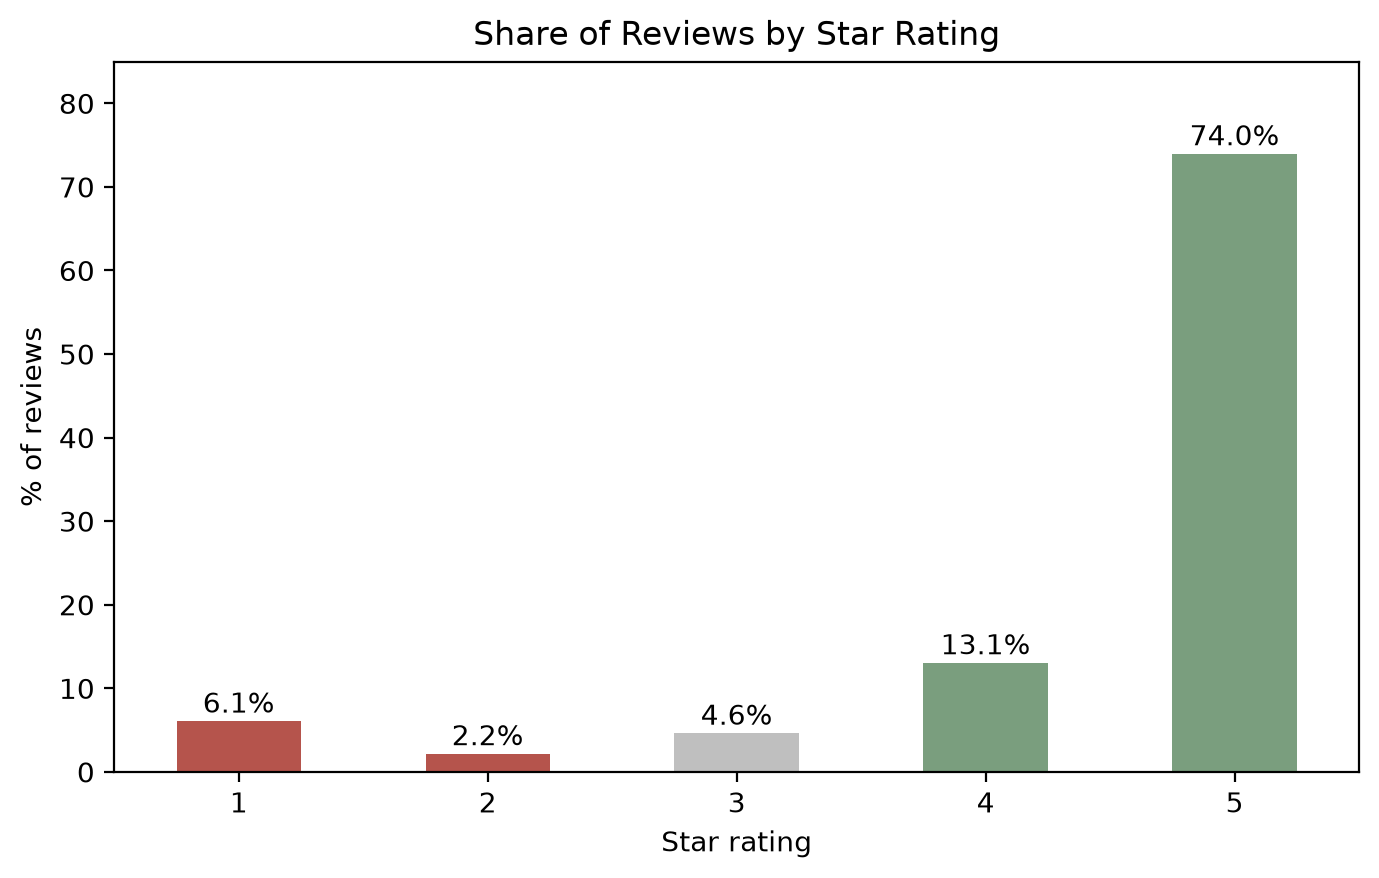

In [7]:
# Showing the star ratings chart
show_figure("01_star_ratings")

Even though unhappy users are a small group, they have a lot more to say. A typical 1- or 2-star review has 17 to 19 words, while a typical 5-star review has only 5, usually something like "great app." This means negative reviews carry most of the detail about what goes wrong.

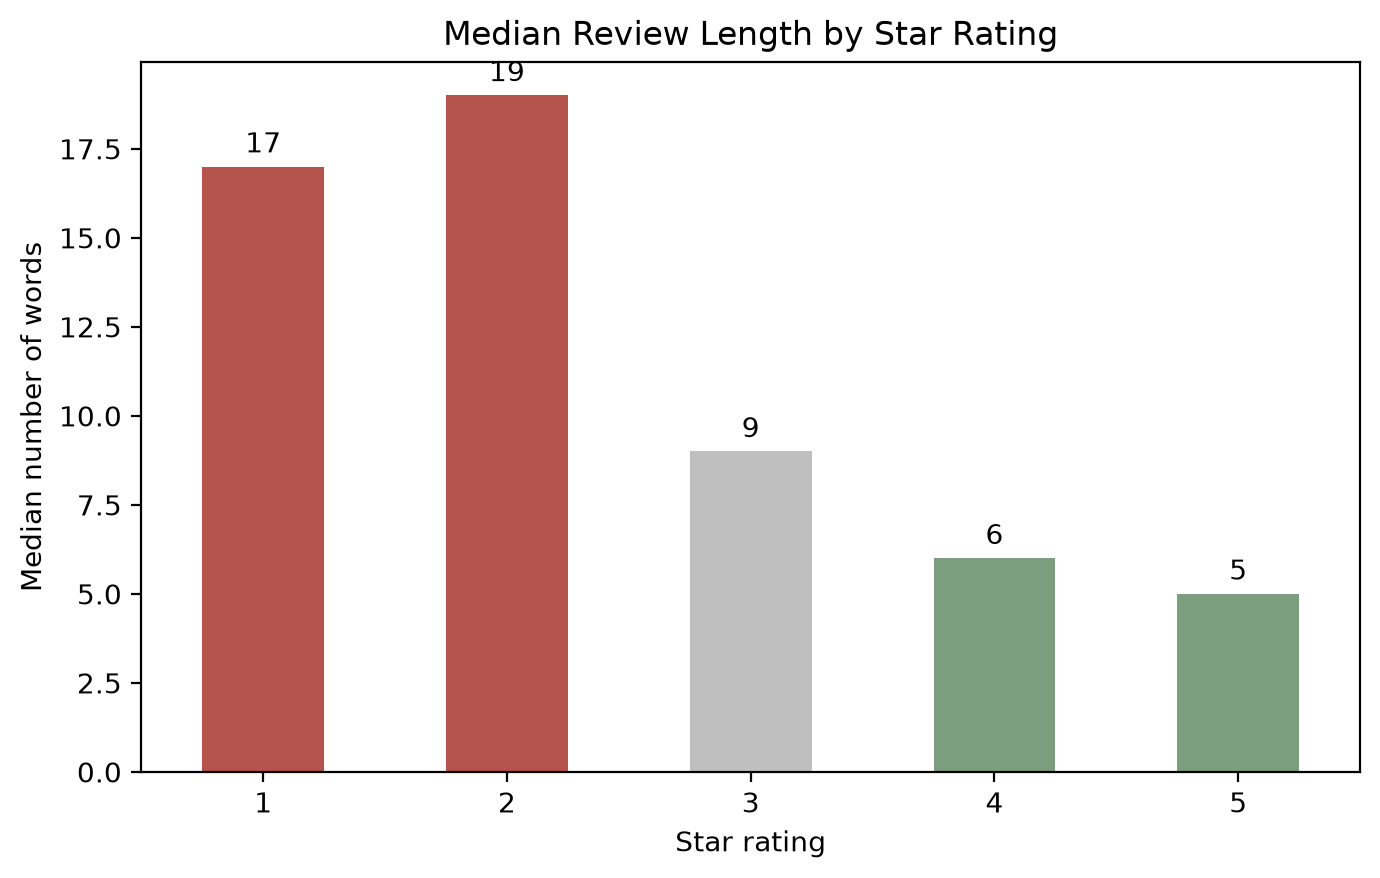

In [8]:
# Showing the length of reviews by star rating chart
show_figure("03_length_by_stars")

The share of negative reviews also changed over time. It stayed around 7.5% for most of August, then jumped to **9.9% in the week ending August 30** and stayed above 9% the week after. Something seems to have made users more unhappy in late August, and finding out what is one of the main goals of this report.

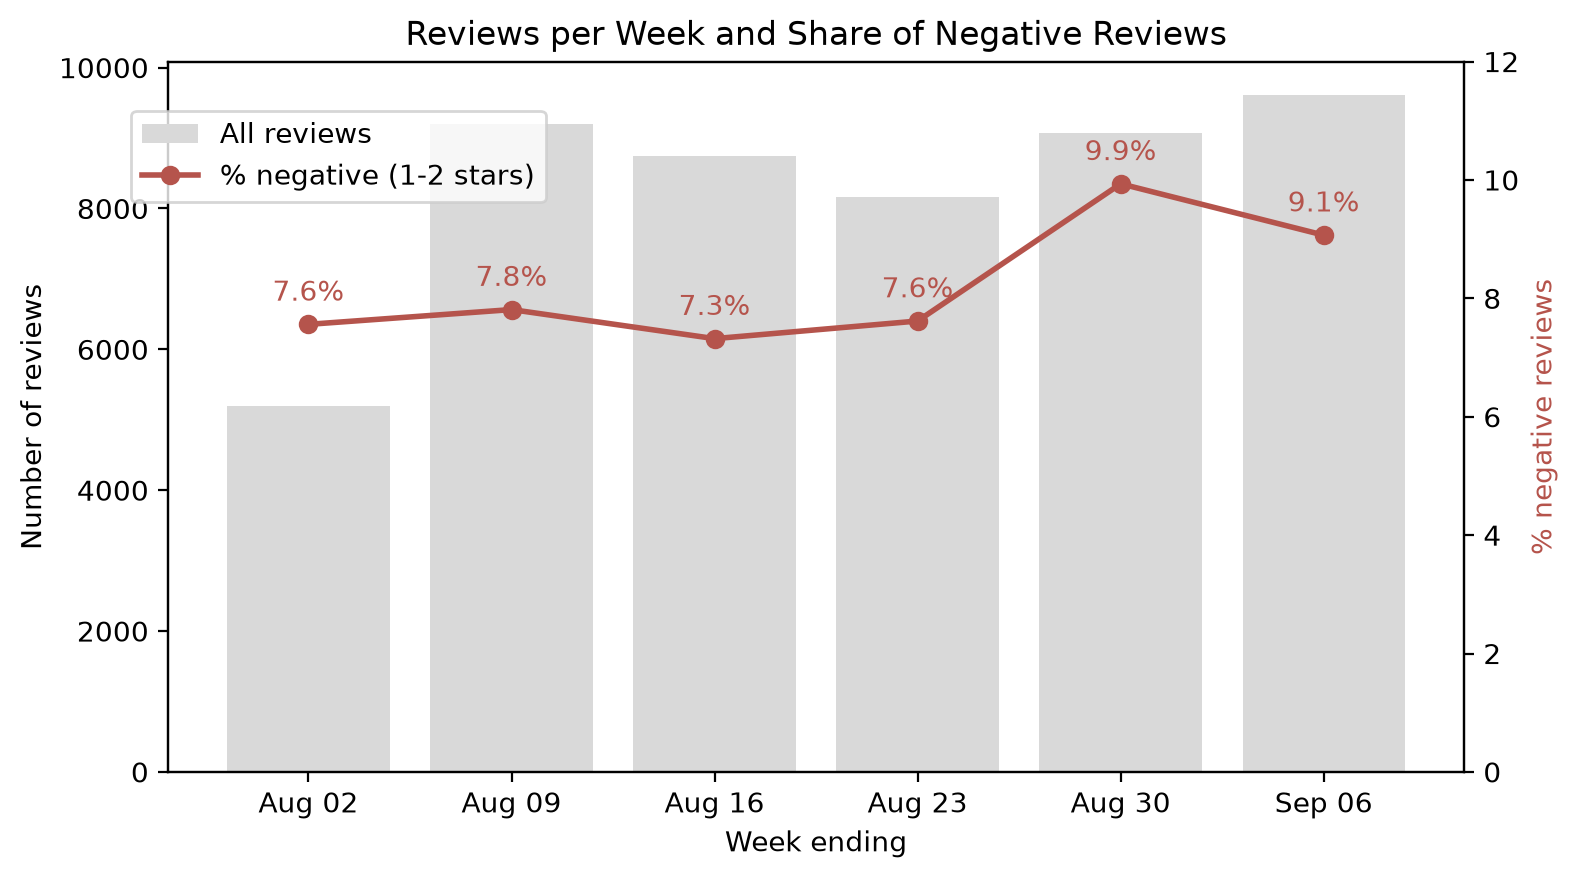

In [9]:
# Showing the reviews over time chart
show_figure("02_reviews_over_time")

**Why we focus on negative reviews:** they are only 8% of all reviews, but they are longer, more detailed, and they rose in late August. For the rest of this report, we look mainly at these **4,147 negative reviews** to understand what users are complaining about.

## 2. What We Learned First

Before using an AI model, we tried three classic text analysis methods in Phase 2: **keywords**, **sentiment analysis**, and **topic modeling**. They are free, fast, and easy to repeat. Each one taught us something useful, but each one also had a clear limit. Together, those limits are the reason we brought in Claude.

### Keywords: the complaints we expected are there
We first compared the words in negative and positive reviews. Simply counting the most common words didn't help much, because words like "learning," "language," and "good" appear everywhere. Comparing how often each word shows up in negative vs. positive reviews was much more useful. For example, "ads" appears in 7.5% of negative reviews but only 0.9% of positive ones, and "energy" in 7.3% vs. 0.7%. Two words we didn't expect also stood out: "AI" and "icon" (Duolingo keeps changing its app icon to sad or strange owl faces).

We then turned these words into simple rules for complaint categories. A review counts as an "ads" complaint, for example, if it mentions "ad," "ads," or "advert."

In [10]:
import re

# Keyword rules for each complaint category (same rules as Notebook 01)
KEYWORD_RULES = {
    "Paywall / subscription": r"\bpremium\b|\bsuper\b|\bmax\b|\bsubscriptions?\b|\bpaid\b|\bpay\b|\bpaying\b|\bmoney\b",
    "Ads": r"\bads?\b|\badverts?\b|\badvertisements?\b",
    "Energy / hearts": r"\benergy\b|\bhearts?\b|\blives\b",
    "AI": r"\bai\b",
    "Streak": r"\bstreaks?\b",
    "Icon / notifications": r"\bicons?\b|\bnotifications?\b",
    "Bugs": r"\bbugs?\b|\bcrash|\bglitch|\bfreez|not working",
}

# % of negative reviews that match each rule
keyword_hits = pd.DataFrame({name: neg["content"].str.contains(rule, case=False, regex=True)
                             for name, rule in KEYWORD_RULES.items()})
keyword_pct = (keyword_hits.mean() * 100).round(1).sort_values(ascending=False)
print(keyword_pct.to_string())
print(f"\nNegative reviews that match no rule: {(~keyword_hits.any(axis=1)).mean():.1%}")

Paywall / subscription    14.4
Ads                        9.4
Energy / hearts            8.6
AI                         6.5
Streak                     5.6
Icon / notifications       4.8
Bugs                       4.7

Negative reviews that match no rule: 61.8%


Paying is the most common keyword complaint (about 14% of negative reviews), followed by ads and energy (about 9% each). But the biggest number is at the bottom: **about 62% of negative reviews don't match any rule.** Some are too short to tell ("so bad"), but many describe a real problem in words our rules don't catch. For example, "I lost my 300 days" is clearly a streak complaint, but it never says "streak."

### Sentiment: it shows who is upset, but not why
Next, we scored every review with VADER, a sentiment tool that rates text from -1 (very negative) to +1 (very positive). On average, the text matches the stars: sentiment goes up from -0.06 for 1-star reviews to 0.53 for 5-star reviews. But the chart below shows the problem. **About one in three 1-star reviews sounds positive**, because people often write things like "I loved this app until the last update." VADER reads the word "loved" and misses the complaint.

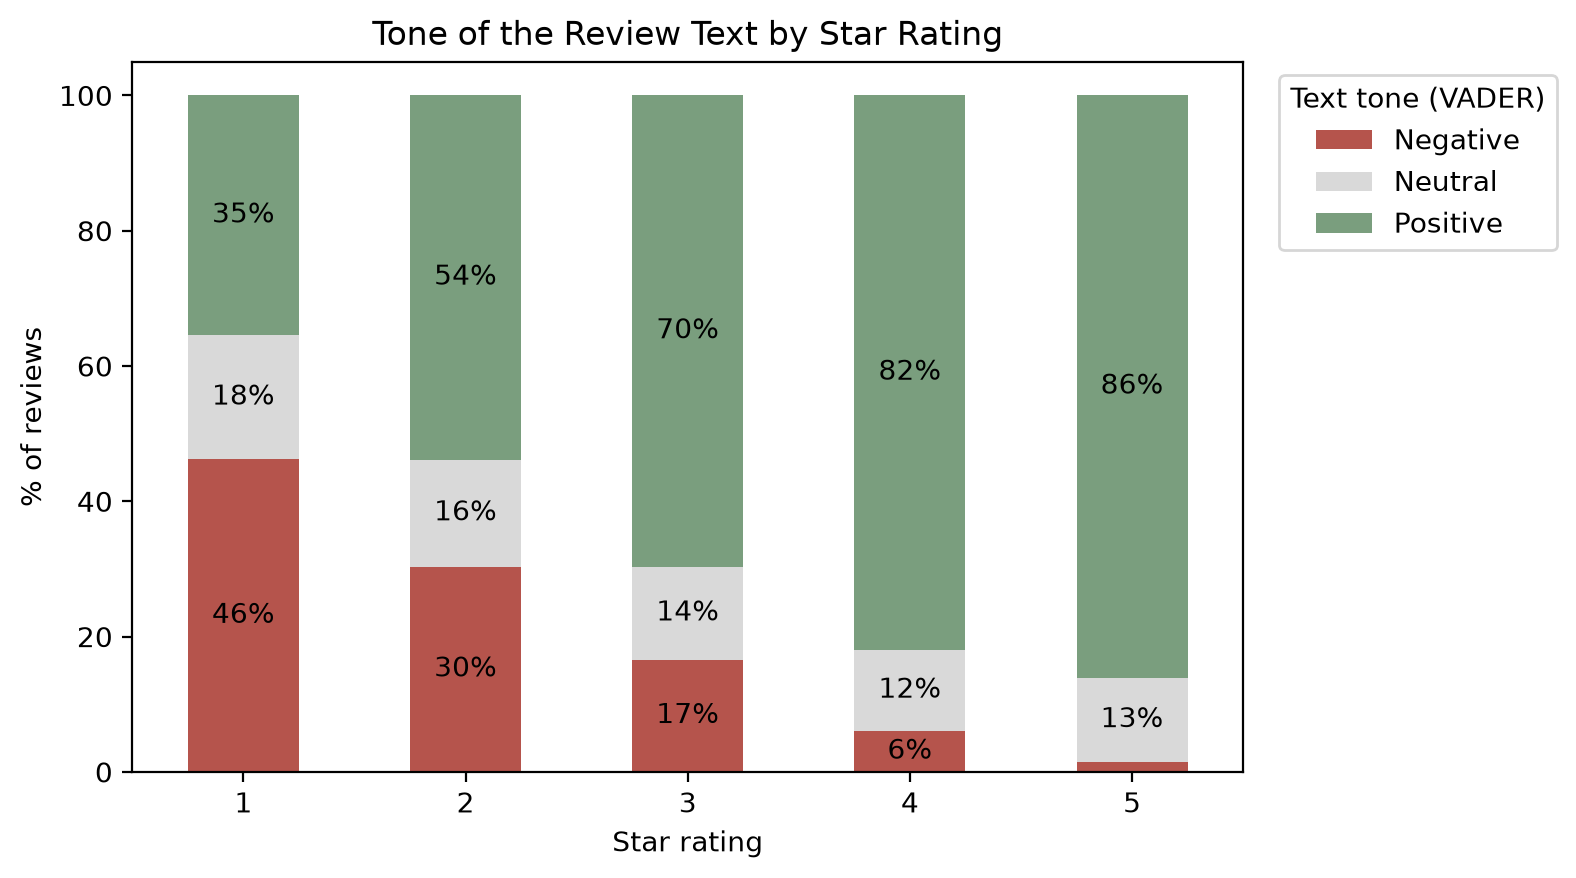

In [11]:
# Showing the text tone by star rating chart
show_figure("06_text_tone_by_stars")

### Topic modeling: it found the main themes, plus some surprises
Finally, we used topic modeling (NMF), which groups reviews by the words they share without us telling it what to look for. We ran it on the 3,267 negative reviews with at least 5 words, after removing generic words like "app," "language," and "good" that appear in almost every review. We tried 6, 8, and 10 topics and kept **10**, because each topic was about one clear theme.

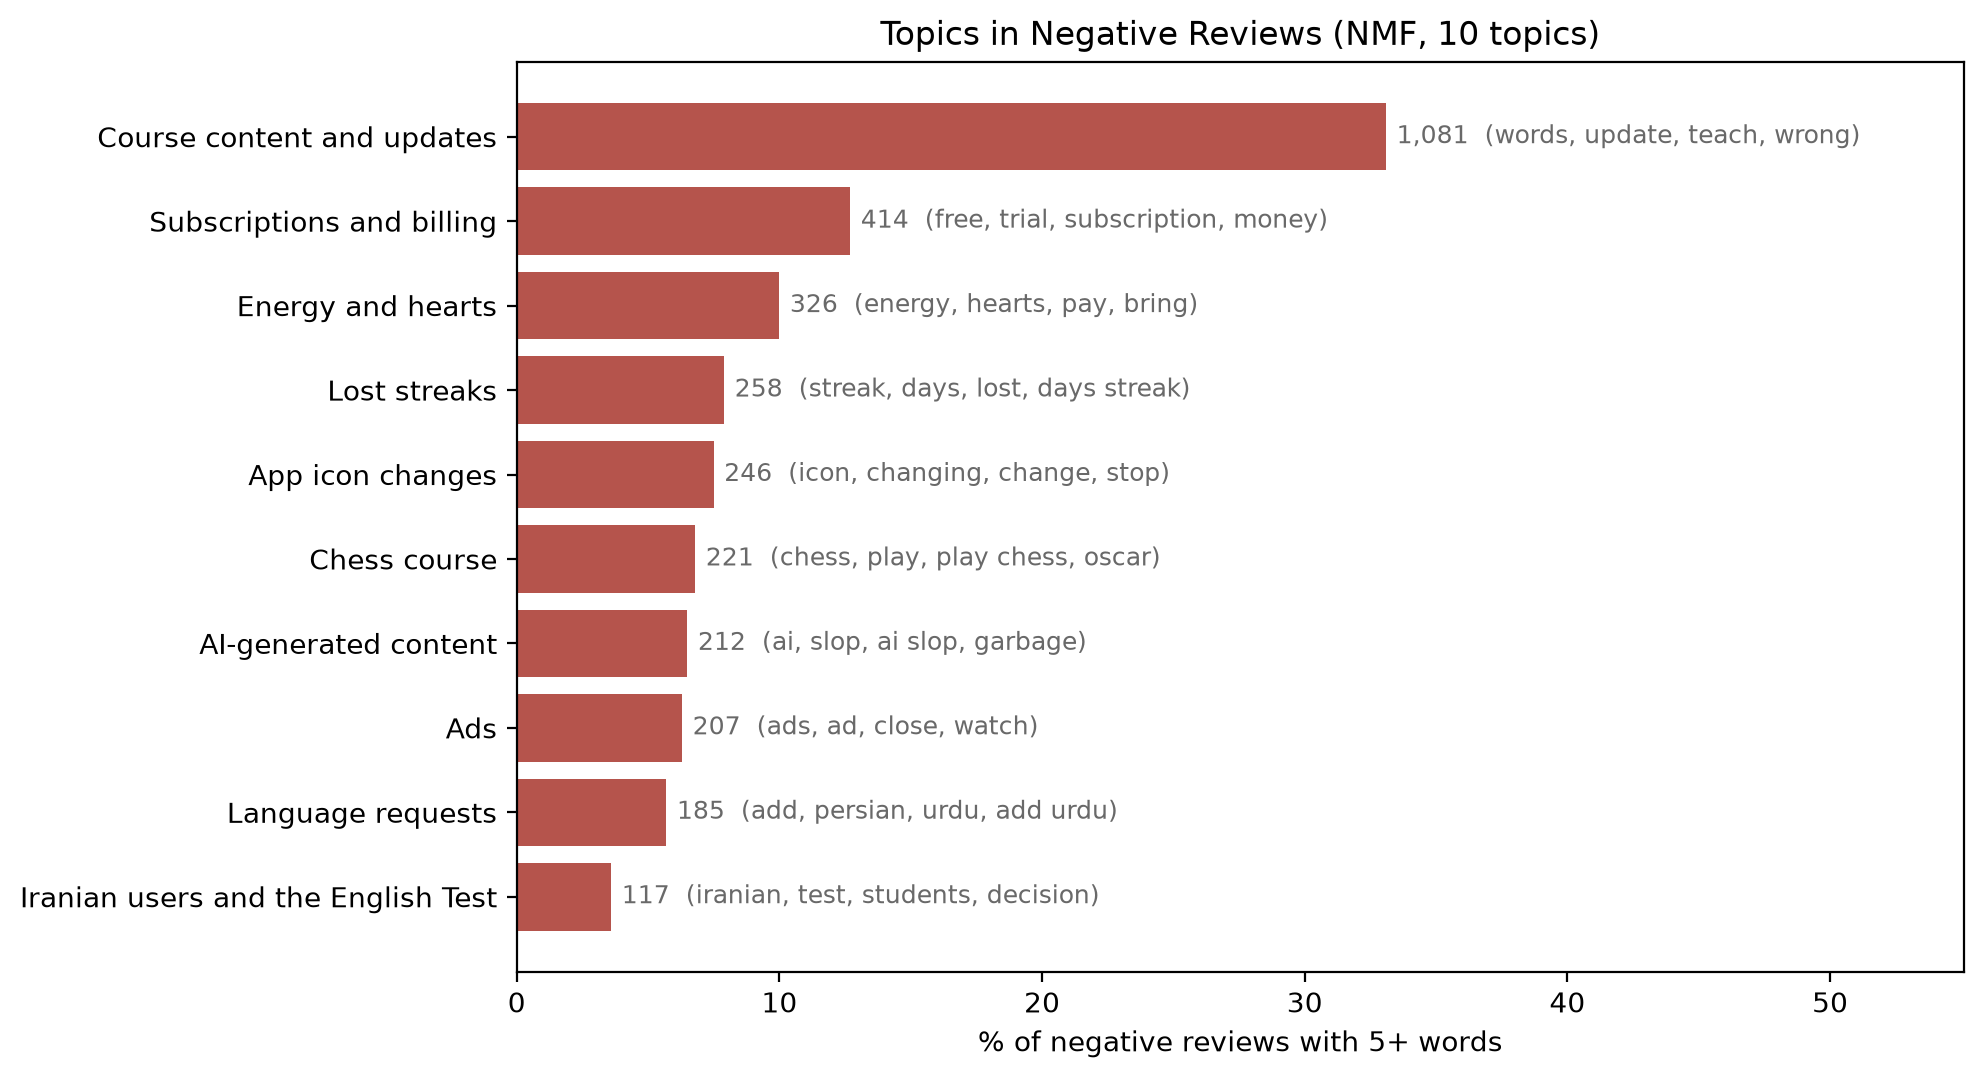

In [13]:
# Showing the topics chart
show_figure("08_topics")

Topic modeling found the same big complaints as our keywords: subscriptions and billing (13%), energy and hearts (10%), lost streaks (8%), and app icon changes (8%). It also found things we didn't expect, like complaints about the new chess course, AI-generated lessons, requests for new languages, and Iranian users who can't take the Duolingo English Test. But it has two limits: each review can only belong to **one** topic, and the biggest topic, "course content and updates" (33%), is too broad to act on.

### What this told us
All three methods point to the same kinds of problems: paying, energy limits, streaks, and the app icon. But none of them could give us a reliable count for every review:
- **Keywords** missed 62% of negative reviews.
- **Sentiment** shows how people feel, not what they complain about.
- **Topics** give each review only one theme, and one theme is too broad.

We needed a tool that could read each review the way a person would, understand the context, and give it **one or more** complaint labels. That's why we used Claude.

## 3. Using Claude to Label Complaints

To get a complaint label for every negative review, we used **Claude** (model `claude-haiku-4-5`), a small and cheap AI model from Anthropic. We sent the reviews in batches of 20 and asked Claude to give each review **one or more** complaint labels from a fixed list. A fixed list keeps the labels consistent, so we can count them, compare them with our keyword rules, and track them over time.

We built this step by step:
1. **Phase 2:** we tested the prompt on 8 reviews. Several reviews didn't fit any category, so we added two new ones ("language_access" and "teaching_quality") and tested again.
2. **Test run:** we labeled 100 random negative reviews to check the labels and estimate the cost.
3. **Full run:** we labeled all 4,147 negative reviews and saved the labels to `data/claude_labels.csv`. This notebook loads those saved labels, so it can be re-run for free, without an API key. The code that called Claude is in Notebook 04.

### Our prompt
This is the exact prompt we sent to Claude. Each category has a short definition, so Claude and a person would apply it the same way. Claude had to answer only with a list of labels for each review, so we could save the answers directly.

In [14]:
# The exact prompt we sent to Claude (version 2). {reviews} is replaced by a numbered batch of 20 reviews.
PROMPT = """You are labeling negative Duolingo app reviews.
Categories:
- energy_hearts: running out of energy or hearts, limits on how much you can practice
- streak: losing or protecting a streak
- ads: too many ads or ads interrupting lessons
- paywall: having to pay, Super/Max/premium, subscription, price, features locked behind payment
- ai: AI features or Duolingo using AI instead of people
- icon_notifications: the changing app icon or pushy notifications
- bugs: crashes, glitches, things not working
- language_access: missing languages, or users in some countries (like Iran) losing access to features
- teaching_quality: lessons that are wrong, confusing, or don't actually teach well
- other: none of the above

A review can have more than one category. Use "other" only if nothing else fits.
Return ONLY a JSON list, with no other text, like: [{"id": 0, "labels": ["streak"]}]

Reviews:
{reviews}"""

print(PROMPT)

You are labeling negative Duolingo app reviews.
Categories:
- energy_hearts: running out of energy or hearts, limits on how much you can practice
- streak: losing or protecting a streak
- ads: too many ads or ads interrupting lessons
- paywall: having to pay, Super/Max/premium, subscription, price, features locked behind payment
- ai: AI features or Duolingo using AI instead of people
- icon_notifications: the changing app icon or pushy notifications
- bugs: crashes, glitches, things not working
- language_access: missing languages, or users in some countries (like Iran) losing access to features
- teaching_quality: lessons that are wrong, confusing, or don't actually teach well
- other: none of the above

A review can have more than one category. Use "other" only if nothing else fits.
Return ONLY a JSON list, with no other text, like: [{"id": 0, "labels": ["streak"]}]

Reviews:
{reviews}


In [15]:
# Loading Claude's saved labels (no API calls needed)
labels = pd.read_csv("../data/claude_labels.csv")
labels["claude_labels"] = labels["claude_labels"].apply(json.loads)

# Applying the stricter "bugs" re-check (explained below): remove "bugs" where the re-check said it isn't a bug
bugs_check = pd.read_csv("../data/claude_bugs_check.csv")
not_bugs = set(bugs_check.loc[~bugs_check["really_bug"], "reviewId"])

def apply_bug_check(row):
    """Take "bugs" off a review's labels if the re-check said it isn't really a bug."""
    if row["reviewId"] in not_bugs:
        return [label for label in row["claude_labels"] if label != "bugs"] or ["other"]
    return row["claude_labels"]

labels["claude_labels"] = labels.apply(apply_bug_check, axis=1)
neg = neg.merge(labels, on="reviewId")

print(f"Negative reviews with Claude labels: {len(neg):,}")
print(f"Reviews with more than one complaint: {(neg['claude_labels'].str.len() > 1).mean():.0%}")

Negative reviews with Claude labels: 4,147
Reviews with more than one complaint: 23%


### Sample outputs
Here are a few real reviews and the labels Claude gave them. Notice that Claude can give one review several labels, and that it understands complaints even when they don't use our keywords, like the chess game showing a loss after a win.

In [16]:
# Examples of negative reviews with their Claude labels
pd.set_option("display.max_colwidth", None)
examples = neg[neg["n_words"].between(8, 35) & neg["claude_labels"].apply(lambda l: l != ["other"])]
examples.sample(6, random_state=1)[["content", "claude_labels"]]

,content,claude_labels
415,I am going to give this only one star because their is a lot of ads,[ads]
2113,"haven't used app in months, never subscribed to an annual plan but they just tried to charge me $99. I've never been so mad in my life. Beware of this scam",[paywall]
1256,used to love the app before all the ai,[ai]
777,"The Math Lessons don't actually teach you anything, What is the point?",[teaching_quality]
3132,because I want to learn English there is no English so I am deleting this app because this is the this is the ugliest app in the world,[language_access]
200,need kannada to english because in karnataka we can't understand as english please look into it,[language_access]


### Checking Claude's work
We didn't want to build on Claude's labels without checking them first, so we checked them in three ways.

**Check 1: Claude vs. our keyword rules.** Claude placed many more reviews into a category. With keywords, 62% of negative reviews didn't match anything; with Claude, only **30%** ended up as "other," and most of those are very short or vague ("so bad," "trash"). The biggest gain was in bugs, because people describe them in many ways ("buttons stop responding," "marks my right answer wrong") without saying "bug." Streak was the only category where keywords found more, and when we read those reviews, many just mentioned a streak ("I hit a 4000 day streak") without complaining about it, so Claude was right.

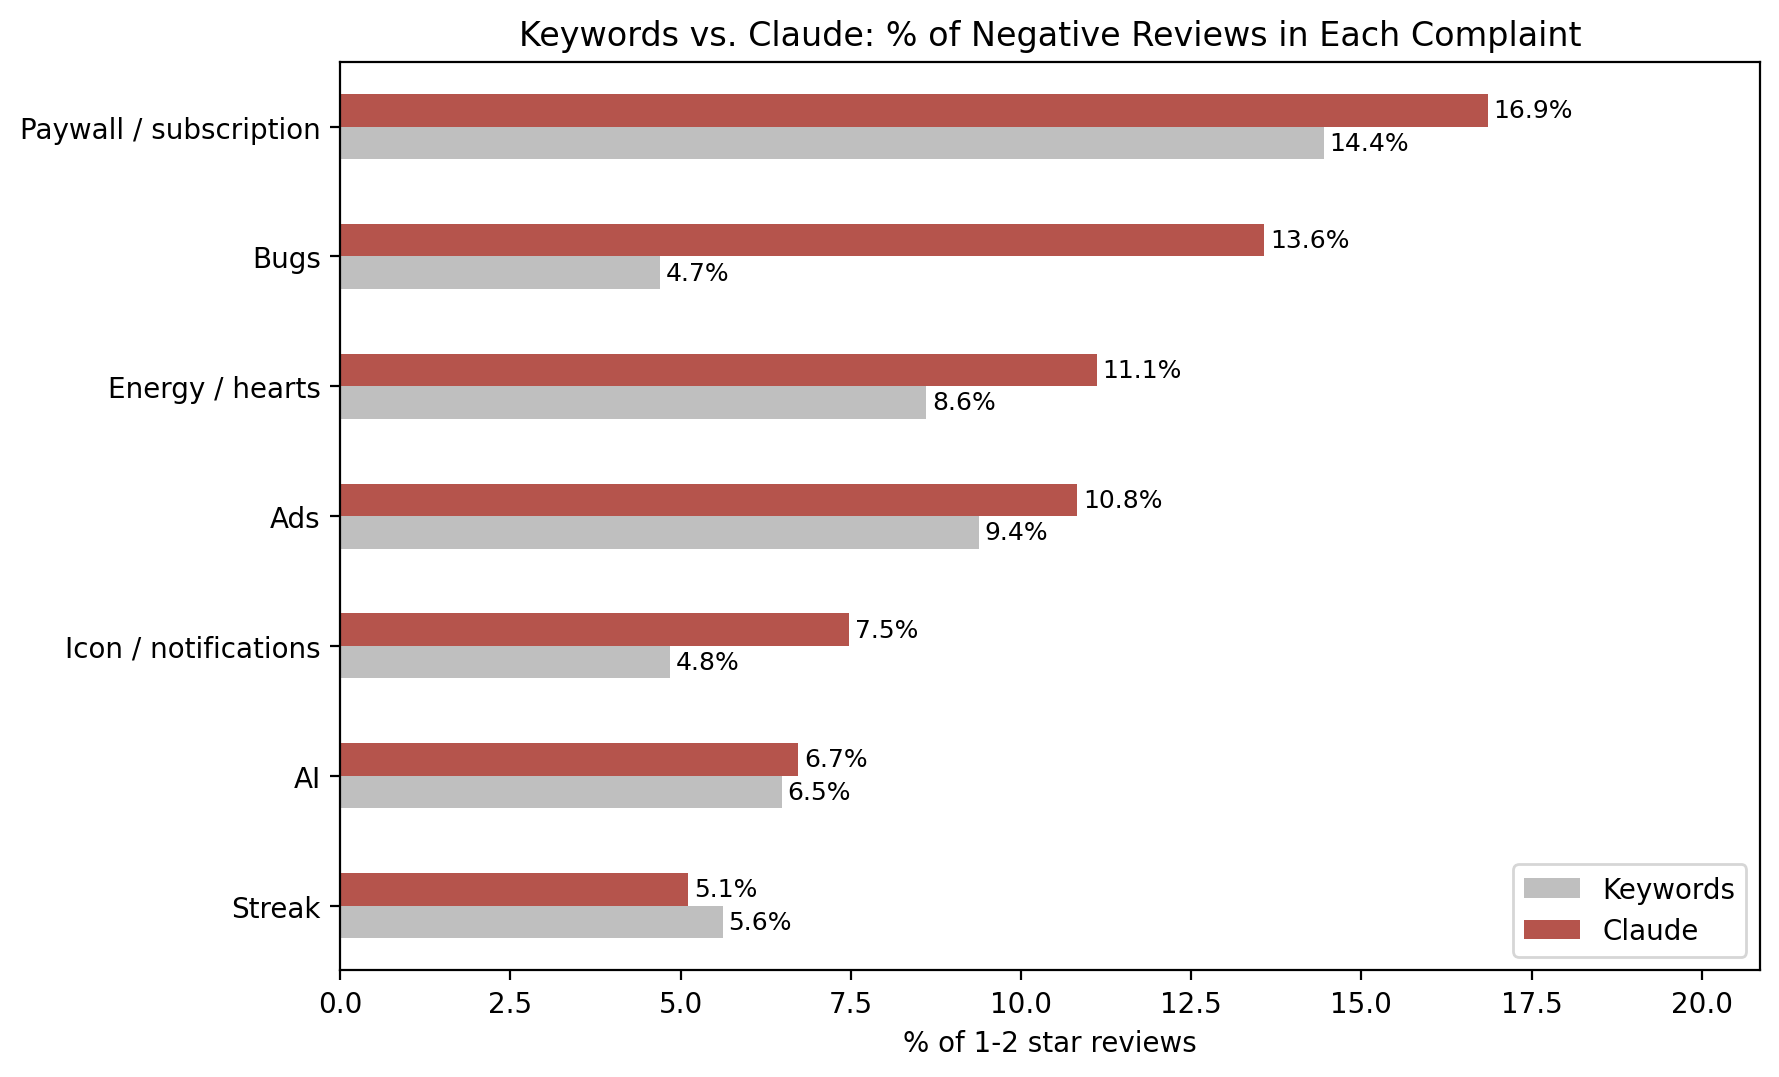

In [17]:
# Showing the comparison of Claude labels vs keyword rules
show_figure("09_claude_vs_keywords")

**Check 2: a stricter re-check for bugs.** When we read reviews where Claude and the keywords disagreed, we noticed Claude was too loose with "bugs." For example, it labeled a complaint about losing chess points as a bug, even though that's about the game rules. Since bugs looked like one of the biggest complaints, we sent only the "bugs" reviews back to Claude with this stricter prompt:

In [18]:
# The stricter prompt we used to re-check only the reviews Claude labeled as "bugs"
BUGS_PROMPT = """Each review below was labeled as a "bug" complaint about the Duolingo app.
Decide if the review really describes a technical problem: crashes, freezing, buttons or features not responding, error messages, lost progress or data because of a glitch, or being charged when the app says there's no subscription.
Complaints about how a feature is designed, game rules (like chess Elo), lesson content, or teaching quality are NOT bugs.
Return ONLY a JSON list, with no other text, like: [{"id": 0, "bug": true}]

Reviews:
{reviews}"""

print(BUGS_PROMPT)

Each review below was labeled as a "bug" complaint about the Duolingo app.
Decide if the review really describes a technical problem: crashes, freezing, buttons or features not responding, error messages, lost progress or data because of a glitch, or being charged when the app says there's no subscription.
Complaints about how a feature is designed, game rules (like chess Elo), lesson content, or teaching quality are NOT bugs.
Return ONLY a JSON list, with no other text, like: [{"id": 0, "bug": true}]

Reviews:
{reviews}


This lowered the number of bug reviews from **772 to 563**, so bugs went from 18.6% to 13.6% of negative reviews. We use the re-checked labels in the rest of this report.

**Check 3: hand-checking 30 random reviews.** Finally, we picked 30 random negative reviews, read each one ourselves, and marked whether Claude's labels were fully right (**y**), partly right (**partial**), or wrong (**n**).

In [19]:
checked = pd.read_csv("../data/hand_check.csv").fillna("")
answers = checked["claude_correct"].str.strip().str.lower()

print(f"Fully correct:  {(answers == 'y').sum()} of {len(checked)} ({(answers == 'y').mean():.0%})")
print(f"Partly correct: {(answers == 'partial').sum()} of {len(checked)}")
print(f"Wrong:          {(answers == 'n').sum()} of {len(checked)}")

# The reviews where Claude wasn't fully right, with our notes
checked.loc[answers != "y", ["content", "claude_labels", "claude_missed", "notes"]]

Fully correct:  24 of 30 (80%)
Partly correct: 4 of 30
Wrong:          2 of 30


,content,claude_labels,claude_missed,notes
2,"pekak aku cakap betul dia pegi cakap Salah ,sampai aku menjerit dia tak dengar pekak app ni","[""teaching_quality""]",bugs,"speech recognition not hearing her (Malay), not about lesson content"
5,I had given 5 stars before. now I took them away because it's been weeks that my app is apparently bugged no way to fix it. because of the bug I cannot do speaking exercises. Other star was taken away because of the wrong pronunciation coming from the AI.,"[""bugs"", ""ai""]",teaching_quality,"wrong pronunciation means the lesson content is wrong, so teaching_quality too"
7,"Nothing but AI slop now, and they can constantly update units of the lessons so thing I have already done can appear again in the future which is just waste of time and app design of you making mistakes being punishing is really bad because you are supposed to learn the language by making mistakes it's just made this way to encourage the buying premium so basically free tier is worthless except just reaching you the most basic stuff.","[""ai"", ""paywall""]","teaching_quality, energy_hearts",also complains about repeated units and being punished for mistakes
18,I paid for a year of Duo Max. It allowed me to use duo max for 5 weeks and now says I have no subscription with them. Will not allow me to do the video calls and also gives me adds again. Charged me $167 for a year only to give me 5 weeks.,"[""paywall"", ""ads""]",bugs,"paid subscription stopped being recognized, that's something not working"
24,heyyooo so I was tryna learn Filipino but the learning for Filipino wasn't really there and I Suck at Filipino especially on subjects and yes I'm a Filipino myself but I hardly know any Filipino words thanks for reading!,"[""teaching_quality""]",,"no real Filipino course, that's a missing language, not bad lessons (borderline)"
28,It is very nice at the beginning but then it needs money to continue,"[""paywall""]",,needs money to continue' sounds like running out of energy (borderline)


Claude was **fully right on 24 of 30 reviews (80%)** and at least partly right on 28 of 30 (93%). Its mistakes followed a pattern. In the partial cases, Claude usually found the main complaint but missed a second one, like a review about AI lessons that also complained about losing hearts. In the two wrong cases, Claude mixed up similar categories: a review in Malay about the app not hearing the user's voice was labeled "teaching quality" instead of "bugs," and a review about a missing Filipino course was labeled "teaching quality" instead of "language access."

Because agreement was high and the mistakes were small, we decided Claude's labels were good enough to build our analysis on. The main lesson is that Claude may **undercount** complaints a little, especially in reviews that mention several problems.

### API usage and cost
Claude charges by the number of tokens (small pieces of words) sent in and received. We kept track of every call. At Haiku 4.5's price of about $1 per million input tokens and $5 per million output tokens, **labeling all 4,147 negative reviews and re-checking bugs cost about $0.70 in total.**

In [20]:
# Tokens recorded in Notebook 04 when we called Claude
PRICE_IN, PRICE_OUT = 1.00, 5.00   # USD per million tokens (claude-haiku-4-5)

usage = pd.DataFrame({
    "step": ["Labeling all reviews (incl. 100-review test)", "Bugs re-check"],
    "input_tokens": [223_696, 47_784],
    "output_tokens": [74_803, 10_465],
})
usage["cost_usd"] = usage["input_tokens"] / 1e6 * PRICE_IN + usage["output_tokens"] / 1e6 * PRICE_OUT
usage.loc[len(usage)] = ["Total", usage["input_tokens"].sum(), usage["output_tokens"].sum(), usage["cost_usd"].sum()]
usage.round(3)

,step,input_tokens,output_tokens,cost_usd
0,Labeling all reviews (incl. 100-review test),223696,74803,0.598
1,Bugs re-check,47784,10465,0.100
2,Total,271480,85268,0.698


### Was Claude worth it?
**Yes, for labeling complaints.** For less than a dollar, Claude labeled every negative review, cut the share of unexplained reviews in half compared to keywords, could give one review several labels, and agreed with us 80% of the time. Doing this by hand would have taken days. It also worked on reviews in other languages and in mixed languages like Hindi-English, which our keyword rules couldn't read at all.

**But it wasn't needed for everything.** Simpler tools were enough for other parts of the project:
- **Star ratings and counts** already told us *who* was unhappy and *when*, with no AI.
- **Keywords** were free and almost as good for complaints that always use the same word, like "ads" or "AI" (6.5% with keywords vs. 6.7% with Claude).
- **Topic modeling** was free and found surprises we hadn't thought of, like the chess course, which helped us choose Claude's categories.

**What we'd do differently:** Claude's answers can change slightly if we run it again, so we saved every label instead of re-running it. To save even more, a team could use Claude only on the reviews that keywords can't place, and use the keyword rules for the rest.